> **Reference copy with outputs.** This notebook was run on Wolverine Glacier on 2026-10-22 (OGGM 1.6.3, preprocessed level 4, W5E5). It shows what the notebook should produce. To run it yourself, open [`notebooks/02_mass_balance_calibration.ipynb`](../notebooks/02_mass_balance_calibration.ipynb), not this copy.

# 02 · Mass balance: calibration and evaluation

OGGM 1.6 calibrates each glacier's mass-balance model to **one number**: the mean geodetic
mass balance of Hugonnet et al. (2021) over 2000–2020. It uses an "informed three-step"
procedure. The precipitation factor comes from a global relation with winter precipitation,
the temperature bias from regional values, and the melt factor is then solved so the mean MB
matches. One number cannot pin down three parameters, so many parameter sets fit equally well.

Wolverine is unusual: it has **seasonal** glaciological balances since 1966 (USGS benchmark
glacier, WGMS id 94). The **winter balance** is mostly accumulation, so it is the observation
that speaks most directly to precipitation amount and phase. This notebook:

1. compares the calibrated model with the annual, winter and summer balances;
2. maps the equifinality between `prcp_fac` and `melt_f`, and asks which pairs also fit the
   seasonal balances;
3. recalibrates under alternative rain/snow schemes, to set up notebook 03.

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from oggm.core.massbalance import mb_calibration_from_scalar_mb

from wolverine_oggm import config, massbalance, phase, plotting

warnings.filterwarnings("ignore", category=RuntimeWarning)
plotting.set_style("paper")
gdir = config.get_glacier_directory()
calib = gdir.read_json("mb_calib")
y_last = config.last_climate_year(gdir)
pd.Series({k: v for k, v in calib.items() if not isinstance(v, dict)})

rgi_id                            RGI60-01.09162
bias                                           0
melt_f                                  5.945867
prcp_fac                                1.011742
temp_bias                              -3.068428
reference_mb                              -762.2
reference_mb_err                           123.9
reference_period           2000-01-01_2020-01-01
baseline_climate_source               GSWP3_W5E5
dtype: object

## Observed seasonal balances

In [2]:
try:
    obs = gdir.get_ref_mb_data()[["WINTER_BALANCE", "SUMMER_BALANCE", "ANNUAL_BALANCE"]]
    obs.columns = ["winter", "summer", "annual"]
except Exception as err:
    raise RuntimeError("This notebook needs the WGMS series (Wolverine is a WGMS reference glacier)") from err
obs = obs.loc[obs.index <= y_last]
print(f"{obs['annual'].notna().sum()} years of annual and {obs['winter'].notna().sum()} of winter balance, "
      f"{obs.index.min()}-{obs.index.max()}")
obs.describe().round(0)

54 years of annual and 54 of winter balance, 1966-2019


,winter,summer,annual
count,54.0,54.0,54.0
mean,2358.0,-2747.0,-389.0
std,943.0,692.0,1223.0
min,1040.0,-4490.0,-2490.0
25%,1818.0,-3172.0,-1132.0
50%,2130.0,-2690.0,-555.0
75%,2630.0,-2190.0,318.0
max,6680.0,-1540.0,3560.0


## Default model vs observations

Both are computed on the **fixed present-day geometry**. The glaciological series uses each
year's real hypsometry, which explains part of any trend difference over decades.
Hydrological years run Oct–Sep and are labelled by the year they end. Winter is October–April.

In [3]:
Default = massbalance.phase_model_class(name="OGGM default")
years = [y for y in obs.index if y >= 1980]      # W5E5 starts in 1979
mod = massbalance.seasonal_balances(Default(gdir), gdir, years)


def scores(m, o):
    out = {}
    for k in ("annual", "winter", "summer"):
        ok = o[k].notna()
        if ok.sum() < 3:
            continue
        a, b = m.loc[ok[ok].index, k], o.loc[ok, k]
        out[k] = {"bias": (a - b).mean(), "rmse": np.sqrt(((a - b) ** 2).mean()), "r": np.corrcoef(a, b)[0, 1]}
    return pd.DataFrame(out).T.round(2)


scores(mod, obs.loc[years])

,bias,rmse,r
annual,51.59,760.37,0.80
winter,187.69,787.41,0.65
summer,-136.10,470.76,0.78


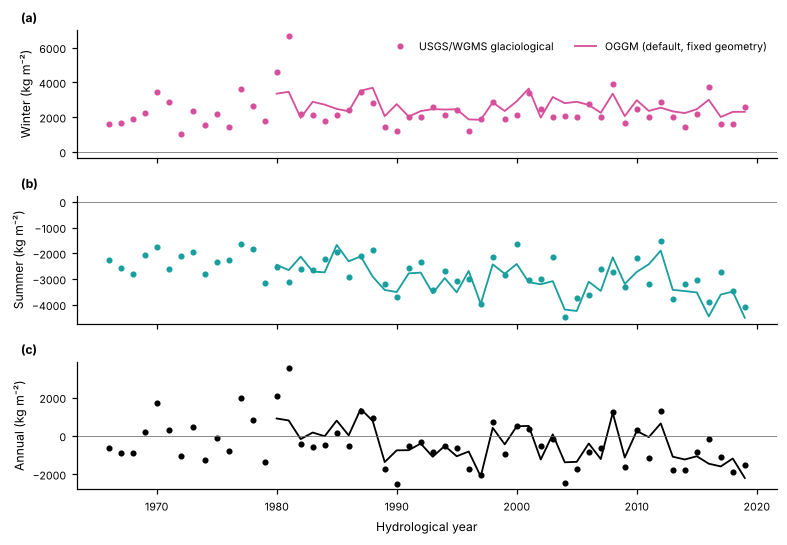

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(plotting.WIDTH_2COL, 5), sharex=True)
for ax, k, c in zip(axes, ("winter", "summer", "annual"), (plotting.SNOW, plotting.RAIN, "k")):
    ax.plot(obs.index, obs[k], "o", ms=3, color=c, label="USGS/WGMS glaciological")
    ax.plot(mod.index, mod[k], "-", color=c, label="OGGM (default, fixed geometry)")
    ax.axhline(0, color=plotting.GREY, lw=0.5)
    ax.set_ylabel(f"{k.capitalize()} (kg m⁻²)")
axes[0].legend(frameon=False, ncol=2)
axes[-1].set_xlabel("Hydrological year")
plotting.label_panels(axes, x=-0.08)
fig.tight_layout()
plotting.test_mode_note(fig)

**What to look for.** A model calibrated only on the 2000–2020 mean can match the annual
balance and still get the seasonal amplitude wrong. A winter balance that is too small, made up
for by a summer balance that is too small, points to too little accumulation (too low a
`prcp_fac`, or too much precipitation counted as rain). That compensation is exactly where
phase-scheme assumptions hide.

## Equifinality: `prcp_fac` vs `melt_f`

For a range of precipitation factors, solve for the melt factor that reproduces the same
reference MB, then score each pair against the seasonal series. Every pair matches the
calibration target exactly. They differ in how they split it into winter and summer.

In [5]:
ref_mb, ref_period = calib["reference_mb"], calib["reference_period"]
rows = []
for pf in np.round(np.linspace(0.6, 1.6, 6) * calib["prcp_fac"], 2):
    try:
        mb_calibration_from_scalar_mb(gdir, ref_mb=ref_mb, ref_period=ref_period, calibrate_param1="melt_f",
                                      prcp_fac=pf, temp_bias=calib["temp_bias"], filesuffix="_eq",
                                      write_to_gdir=True, overwrite_gdir=True)
    except Exception as err:          # no melt_f in OGGM's allowed range can close the budget
        print(f"prcp_fac {pf}: {err.__class__.__name__}")
        continue
    c = gdir.read_json("mb_calib", filesuffix="_eq")
    m = massbalance.seasonal_balances(massbalance.with_settings(Default, calib_suffix="_eq")(gdir), gdir, years)
    s = scores(m, obs.loc[years])
    rows.append({"prcp_fac": pf, "melt_f": c["melt_f"], **{f"{k}_{q}": s.loc[k, q] for k in s.index for q in s.columns}})
eq = pd.DataFrame(rows).set_index("prcp_fac")
eq

,melt_f,annual_bias,annual_rmse,annual_r,winter_bias,winter_rmse,winter_r,summer_bias,summer_rmse,summer_r
prcp_fac,,,,,,,,,,
0.61,4.172460,-114.11,869.31,0.79,-849.05,1183.86,0.65,734.94,852.85,0.78
0.81,5.131260,-75.38,799.33,0.79,-333.13,856.75,0.65,257.75,500.86,0.78
1.01,6.090060,-36.65,760.62,0.80,182.79,786.46,0.65,-219.44,505.10,0.78
1.21,7.048860,2.08,757.98,0.80,698.71,1027.14,0.65,-696.63,860.32,0.78
1.42,8.055599,42.75,794.36,0.80,1240.43,1451.69,0.65,-1197.68,1329.22,0.78
1.62,9.014399,81.48,861.74,0.80,1756.35,1917.16,0.65,-1674.87,1799.28,0.78


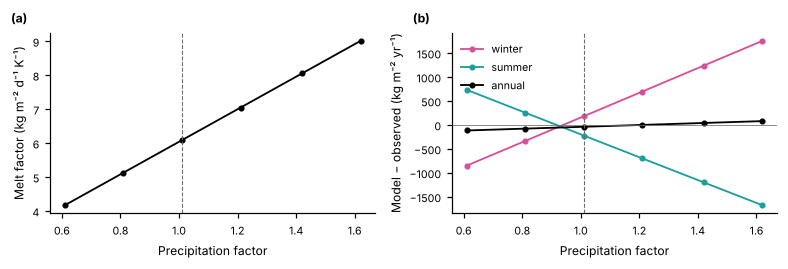

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(plotting.WIDTH_2COL, 2.5))
axes[0].plot(eq.index, eq["melt_f"], "k-o", ms=3)
axes[0].axvline(calib["prcp_fac"], color=plotting.GREY, ls="--", lw=0.7)
axes[0].set_xlabel("Precipitation factor")
axes[0].set_ylabel("Melt factor (kg m⁻² d⁻¹ K⁻¹)")
for k, c in (("winter", plotting.SNOW), ("summer", plotting.RAIN), ("annual", "k")):
    if f"{k}_bias" in eq:
        axes[1].plot(eq.index, eq[f"{k}_bias"], "-o", ms=3, color=c, label=k)
axes[1].axhline(0, color=plotting.GREY, lw=0.5)
axes[1].axvline(calib["prcp_fac"], color=plotting.GREY, ls="--", lw=0.7)
axes[1].set_xlabel("Precipitation factor")
axes[1].set_ylabel("Model − observed (kg m⁻² yr⁻¹)")
axes[1].legend(frameon=False)
plotting.label_panels(axes)
fig.tight_layout()
plotting.test_mode_note(fig)

The precipitation factor where the winter bias crosses zero is the one the seasonal data
favour. That is a defensible alternative calibration for Wolverine, and one hypothesis to carry
into notebook 03.

## Phase scheme changes the calibration

If the rain/snow split changes, the calibration compensates. More rain means less
accumulation, so a lower melt factor is needed to hit the same mean MB. Recalibrate `melt_f`
for several schemes, holding `prcp_fac` and `temp_bias`, and compare the winter balance, which
the calibration did not see.

In [7]:
spread = config.daily_temp_spread(gdir)   # W5E5 daily temperature s.d., or 2.5 K without it
schemes = {
    "OGGM ramp 0–2 °C": massbalance.phase_model_class(),
    "Threshold 0 °C": massbalance.phase_model_class(phase.Threshold(0.0)),
    "Threshold 2 °C": massbalance.phase_model_class(phase.Threshold(2.0)),
    "Jennings RH90 + daily spread": massbalance.phase_model_class(phase.Jennings2018(90), temp_std=spread),
    "OGGM ramp + daily spread": massbalance.phase_model_class(phase.STANDARD_CURVES["oggm"], temp_std=spread),
}
cal, rows = {}, []
for k, (label, cls) in enumerate(schemes.items()):
    cal[label] = massbalance.recalibrate(gdir, cls, f"_ph{k}")
    m = massbalance.seasonal_balances(cal[label](gdir), gdir, years)
    s = scores(m, obs.loc[years])
    rows.append({"scheme": label, "melt_f": cal[label].calib["melt_f"],
                 "winter_solid_prcp": m["winter_solid_prcp"].mean(), "winter_liquid_prcp": m["winter_liquid_prcp"].mean(),
                 "winter_bias": s.loc["winter", "bias"] if "winter" in s.index else np.nan,
                 "winter_r": s.loc["winter", "r"] if "winter" in s.index else np.nan,
                 "annual_r": s.loc["annual", "r"]})
phase_table = pd.DataFrame(rows).set_index("scheme").round(2)
phase_table

,melt_f,winter_solid_prcp,winter_liquid_prcp,winter_bias,winter_r,annual_r
scheme,,,,,,
OGGM ramp 0–2 °C,6.10,2622.92,7.63,187.28,0.65,0.80
Threshold 0 °C,5.87,2612.74,17.81,177.72,0.65,0.79
Threshold 2 °C,6.30,2628.00,2.55,191.83,0.65,0.80
Jennings RH90 + daily spread,6.11,2584.67,45.88,149.00,0.65,0.80
OGGM ramp + daily spread,6.03,2582.82,47.73,147.36,0.65,0.80


Notebook 03 uses these recalibrated models (saved as `mb_calib_ph*.json` in the glacier
directory) for dynamic runs.

**Things to try**

* Calibrate on the observed **winter** balance directly: fit `prcp_fac` so the mean winter bias
  is zero, then `melt_f` to the geodetic mean. That is a two-target calibration
  (`calibrate_param1="prcp_fac"` against winter-only MB needs a small custom loop; see
  `seasonal_balances`).
* Repeat for the 1966–2000 period, to check the calibration is stable in time.